# Assignment Beta – Question 4: Evaluating an LLM sentiment classifier
**Syed Ukkashah – 23K-0055**

300 reviews, 3 classes (Positive, Negative, Neutral). Confusion matrices: rows = actual, columns = predicted.
All metrics are computed by hand with numpy so the working is visible. `sklearn` and `nltk` are used only as cross-checks.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

classes = ["Positive", "Negative", "Neutral"]

stage1 = np.array([[100,  5, 15],
                   [  8, 80, 12],
                   [ 20, 10, 50]])

stage2 = np.array([[106,  4, 10],
                   [  6, 84, 10],
                   [  9,  7, 64]])

pd.DataFrame(stage1, index=[f"actual {c}" for c in classes], columns=[f"pred {c}" for c in classes])

,pred Positive,pred Negative,pred Neutral
actual Positive,100,5,15
actual Negative,8,80,12
actual Neutral,20,10,50


## 1. Overall accuracy with a 95% confidence interval

$\text{Accuracy} = \dfrac{\text{trace}}{n}$. **Wald (normal-approximation) interval:** $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$.
The **Wilson** interval is also shown. It is better behaved when $\hat p$ is near 0 or 1, but with n = 300 the two are close.

In [2]:
def accuracy_ci(cm, z=1.96, show=True):
    n = cm.sum()
    correct = np.trace(cm)
    p = correct / n
    se = np.sqrt(p * (1 - p) / n)
    wald = (p - z * se, p + z * se)
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    wilson = (centre - half, centre + half)
    if show:
        print(f"accuracy = {correct}/{n} = {p:.4f}")
        print(f"SE = sqrt({p:.4f} * {1 - p:.4f} / {n}) = {se:.4f}")
        print(f"95% Wald CI   = {p:.4f} ± {z * se:.4f} = [{wald[0]:.4f}, {wald[1]:.4f}]")
        print(f"95% Wilson CI = [{wilson[0]:.4f}, {wilson[1]:.4f}]")
    return p, wald, wilson

acc1, wald1, wilson1 = accuracy_ci(stage1)

accuracy = 230/300 = 0.7667
SE = sqrt(0.7667 * 0.2333 / 300) = 0.0244
95% Wald CI   = 0.7667 ± 0.0479 = [0.7188, 0.8145]
95% Wilson CI = [0.7156, 0.8110]


## 2. Precision, recall and F1 per class

* Precision = TP / (column total): of everything *predicted* as the class, how much was right.
* Recall = TP / (row total): of everything that *is* the class, how much was found.
* $F1 = 2PR/(P+R)$

In [3]:
def per_class_prf(cm):
    tp = np.diag(cm)
    precision = tp / cm.sum(axis=0)
    recall = tp / cm.sum(axis=1)
    f1 = 2 * precision * recall / (precision + recall)
    return pd.DataFrame({"TP": tp, "predicted (col)": cm.sum(axis=0), "actual (row)": cm.sum(axis=1),
                         "precision": precision, "recall": recall, "F1": f1}, index=classes)

prf1 = per_class_prf(stage1)
for c in classes:
    r = prf1.loc[c]
    print(f"{c:8s}: P = {int(r.TP)}/{int(r['predicted (col)'])} = {r.precision:.4f}   "
          f"R = {int(r.TP)}/{int(r['actual (row)'])} = {r.recall:.4f}   F1 = {r.F1:.4f}")
prf1.round(4)

Positive: P = 100/128 = 0.7812   R = 100/120 = 0.8333   F1 = 0.8065
Negative: P = 80/95 = 0.8421   R = 80/100 = 0.8000   F1 = 0.8205
Neutral : P = 50/77 = 0.6494   R = 50/80 = 0.6250   F1 = 0.6369


,TP,predicted (col),actual (row),precision,recall,F1
Positive,100,128,120,0.7812,0.8333,0.8065
Negative,80,95,100,0.8421,0.8000,0.8205
Neutral,50,77,80,0.6494,0.6250,0.6369


## 3. Macro, weighted and micro F1

* **Macro:** the plain mean of the three F1s. Every class counts equally.
* **Weighted:** the mean weighted by support (row totals 120, 100, 80).
* **Micro:** pool TP, FP and FN over all classes. In single-label multi-class classification every error is one FP *and* one FN, so micro-P = micro-R = micro-F1 = **accuracy**.

In [4]:
def averaged_f1(cm, show=True):
    prf = per_class_prf(cm)
    support = cm.sum(axis=1)
    macro = prf.F1.mean()
    weighted = (prf.F1 * support).sum() / support.sum()
    tp = np.trace(cm); fp = fn = cm.sum() - tp
    micro = 2 * tp / (2 * tp + fp + fn)
    if show:
        print("macro F1    = (" + " + ".join(f"{f:.4f}" for f in prf.F1) + f") / 3 = {macro:.4f}")
        print("weighted F1 = (" + " + ".join(f"{s}*{f:.4f}" for s, f in zip(support, prf.F1)) + f") / {support.sum()} = {weighted:.4f}")
        print(f"micro F1    = 2*{tp} / (2*{tp} + {fp} + {fn}) = {micro:.4f}  (= accuracy)")
    return macro, weighted, micro

macro1, weighted1, micro1 = averaged_f1(stage1)

macro F1    = (0.8065 + 0.8205 + 0.6369) / 3 = 0.7546
weighted F1 = (120*0.8065 + 100*0.8205 + 80*0.6369) / 300 = 0.7659
micro F1    = 2*230 / (2*230 + 70 + 70) = 0.7667  (= accuracy)


In [5]:
# cross-check with sklearn by expanding the confusion matrix back into label lists
from sklearn.metrics import classification_report, f1_score

def to_labels(cm):
    y_true, y_pred = [], []
    for i in range(3):
        for j in range(3):
            y_true += [i] * cm[i, j]; y_pred += [j] * cm[i, j]
    return y_true, y_pred

yt, yp = to_labels(stage1)
print(classification_report(yt, yp, target_names=classes, digits=4))

              precision    recall  f1-score   support

    Positive     0.7812    0.8333    0.8065       120
    Negative     0.8421    0.8000    0.8205       100
     Neutral     0.6494    0.6250    0.6369        80

    accuracy                         0.7667       300
   macro avg     0.7576    0.7528    0.7546       300
weighted avg     0.7664    0.7667    0.7659       300



## 4. Interpreting Stage 1

**Where it fails:**
* **Neutral is the weak class.** Recall is 50/80 = 0.625, so more than a third of neutral reviews get a polar label, and **20 of the 30 misses are called Positive**. Precision is also the lowest (50/77 = 0.649): 15 Positive and 12 Negative reviews are pushed *into* Neutral.
* **Positive ↔ Neutral is the main confusion:** 20 + 15 = 35 of the 70 errors (50%). Negative is the cleanest class (recall 0.80, precision 0.84). Negative ↔ Positive mistakes are rare (5 + 8), so the model understands polarity well. Its problem is where the boundary of "no clear opinion" lies.
* Without a definition, the model is inferring what "Neutral" means. Mixed reviews ("late delivery but good product") are especially ambiguous, and an LLM tends to lean positive on politely worded text.

**Recommended changes:**
1. **Define every label in the prompt**, especially Neutral = factual, mixed, or no clear opinion.
2. **Add few-shot examples**, two per class, deliberately including *borderline mixed* reviews.
3. **Constrain the output** to exactly one label (or a JSON field) so parsing never introduces errors.
4. **Check calibration and ordering effects:** rerun with several example orderings, and if needed use log-probabilities with a tuned threshold for Neutral.
5. **Error-driven iteration:** read the 35 Positive/Neutral confusions, then add the most common failure patterns as examples.

Stage 2 implements changes 1 and 2.

## 5. Stage 2 (improved prompt) and comparison

In [6]:
acc2, wald2, wilson2 = accuracy_ci(stage2)
print()
prf2 = per_class_prf(stage2)
macro2, weighted2, micro2 = averaged_f1(stage2)
prf2.round(4)

accuracy = 254/300 = 0.8467
SE = sqrt(0.8467 * 0.1533 / 300) = 0.0208
95% Wald CI   = 0.8467 ± 0.0408 = [0.8059, 0.8874]
95% Wilson CI = [0.8015, 0.8830]

macro F1    = (0.8797 + 0.8615 + 0.7805) / 3 = 0.8406
weighted F1 = (120*0.8797 + 100*0.8615 + 80*0.7805) / 300 = 0.8472
micro F1    = 2*254 / (2*254 + 46 + 46) = 0.8467  (= accuracy)


,TP,predicted (col),actual (row),precision,recall,F1
Positive,106,121,120,0.8760,0.8833,0.8797
Negative,84,95,100,0.8842,0.8400,0.8615
Neutral,64,84,80,0.7619,0.8000,0.7805


In [7]:
compare = pd.DataFrame({
    "Stage 1 (zero-shot)": [acc1, *prf1.F1, macro1, weighted1, micro1],
    "Stage 2 (definition + few-shot)": [acc2, *prf2.F1, macro2, weighted2, micro2],
}, index=["accuracy", "F1 Positive", "F1 Negative", "F1 Neutral", "macro F1", "weighted F1", "micro F1"])
compare["change"] = compare.iloc[:, 1] - compare.iloc[:, 0]
print(f"95% CI  Stage 1: [{wald1[0]:.4f}, {wald1[1]:.4f}]   Stage 2: [{wald2[0]:.4f}, {wald2[1]:.4f}]")
compare.round(4)

95% CI  Stage 1: [0.7188, 0.8145]   Stage 2: [0.8059, 0.8874]


,Stage 1 (zero-shot),Stage 2 (definition + few-shot),change
accuracy,0.7667,0.8467,0.0800
F1 Positive,0.8065,0.8797,0.0732
F1 Negative,0.8205,0.8615,0.0410
F1 Neutral,0.6369,0.7805,0.1435
macro F1,0.7546,0.8406,0.0859
weighted F1,0.7659,0.8472,0.0812
micro F1,0.7667,0.8467,0.0800


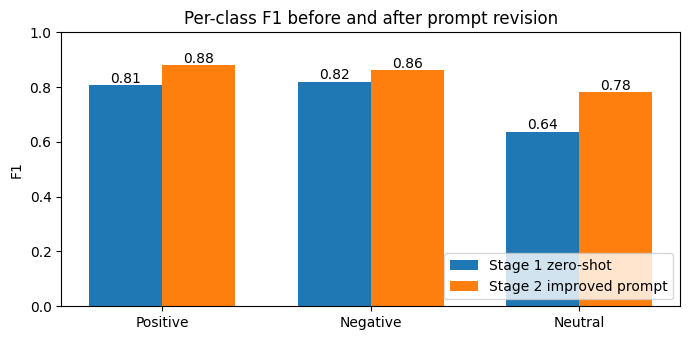

In [8]:
x = np.arange(3); w = 0.35
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(x - w/2, prf1.F1, w, label="Stage 1 zero-shot")
ax.bar(x + w/2, prf2.F1, w, label="Stage 2 improved prompt")
for i in range(3):
    ax.text(i - w/2, prf1.F1.iloc[i] + 0.01, f"{prf1.F1.iloc[i]:.2f}", ha="center")
    ax.text(i + w/2, prf2.F1.iloc[i] + 0.01, f"{prf2.F1.iloc[i]:.2f}", ha="center")
ax.set_xticks(x, classes); ax.set_ylim(0, 1); ax.set_ylabel("F1"); ax.legend(loc="lower right")
ax.set_title("Per-class F1 before and after prompt revision")
plt.tight_layout(); plt.savefig("q4_f1_comparison.png", dpi=150); plt.show()

**Comparison:**
* Accuracy rises from 0.767 to 0.847 (+8.0 points). The two 95% CIs barely overlap, so the gain is very unlikely to be noise. (A paired McNemar test would be the proper check, but it needs per-review predictions, which we don't have.)
* **Neutral improves the most:** recall goes from 50/80 to 64/80, and Neutral→Positive errors fall from 20 to 9. This is exactly the error the new definition and the borderline examples were aimed at.
* Positive and Negative F1 also improve, because fewer of them are dumped into Neutral (15→10 and 12→10). The fix did not simply move errors around.
* Macro F1 gains more than weighted F1, because the smallest class (Neutral) gained the most.

## 6. Prompt stability across five example orderings
The **sample** standard deviation (ddof = 1) is the right choice here because the five runs are a sample of possible orderings.

In [9]:
runs = np.array([0.847, 0.840, 0.853, 0.837, 0.850])
mean = runs.mean()
sd_sample = runs.std(ddof=1)
sd_pop = runs.std(ddof=0)
print("deviations from mean:", np.round(runs - mean, 4))
print(f"mean = {runs.sum():.3f} / 5 = {mean:.4f}")
print(f"sample SD (n-1) = sqrt({((runs - mean)**2).sum():.6f} / 4) = {sd_sample:.4f}")
print(f"population SD (n) = {sd_pop:.4f}")
print(f"\nResult: {mean:.4f} ± {sd_sample:.4f}   (range {runs.min():.3f} – {runs.max():.3f}, i.e. {round((runs.max()-runs.min())*300)} reviews)")

deviations from mean: [ 0.0016 -0.0054  0.0076 -0.0084  0.0046]
mean = 4.227 / 5 = 0.8454
sample SD (n-1) = sqrt(0.000181 / 4) = 0.0067
population SD (n) = 0.0060

Result: 0.8454 ± 0.0067   (range 0.837 – 0.853, i.e. 5 reviews)


**Stability:** the spread is about ±0.006 (0.6 points, about 2 reviews out of 300). The whole range (0.837–0.853) sits inside the binomial sampling error of a single run (≈ ±0.04), and every ordering beats the zero-shot 0.767 by a wide margin. The prompt is **stable with respect to example order**, so the Stage 2 improvement comes from the content of the prompt, not from a lucky ordering. The reported Stage 2 accuracy (0.847) matches the mean.

## 7. Justification quality: BLEU-4, ROUGE, METEOR

* Reference: `the delivery was late but the product quality is good` (10 tokens)
* Candidate: `the product quality is good but delivery was slow` (9 tokens)

In [10]:
from collections import Counter
from math import exp, log

reference = "the delivery was late but the product quality is good".split()
candidate = "the product quality is good but delivery was slow".split()

def ngrams(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

### BLEU-4
$BLEU = BP \cdot \exp\big(\tfrac14 \sum_{n=1}^{4} \ln p_n\big)$, where $p_n$ is the clipped n-gram precision and $BP = e^{1 - r/c}$ when $c < r$.

In [11]:
def bleu4(cand, ref, show=True):
    log_sum = 0
    for n in range(1, 5):
        c_counts, r_counts = Counter(ngrams(cand, n)), Counter(ngrams(ref, n))
        matched = sum(min(count, r_counts[g]) for g, count in c_counts.items())
        total = sum(c_counts.values())
        if show:
            hits = [" ".join(g) for g in c_counts if r_counts[g]]
            print(f"p{n} = {matched}/{total} = {matched/total:.4f}   matched: {hits}")
        log_sum += log(matched / total)
    c, r = len(cand), len(ref)
    bp = 1.0 if c > r else exp(1 - r / c)
    score = bp * exp(log_sum / 4)
    if show:
        print(f"BP = exp(1 - {r}/{c}) = {bp:.4f}")
        print(f"BLEU-4 = {bp:.4f} * exp({log_sum:.4f} / 4) = {score:.4f}")
    return score

bleu = bleu4(candidate, reference)

p1 = 8/9 = 0.8889   matched: ['the', 'product', 'quality', 'is', 'good', 'but', 'delivery', 'was']
p2 = 5/8 = 0.6250   matched: ['the product', 'product quality', 'quality is', 'is good', 'delivery was']
p3 = 3/7 = 0.4286   matched: ['the product quality', 'product quality is', 'quality is good']
p4 = 2/6 = 0.3333   matched: ['the product quality is', 'product quality is good']
BP = exp(1 - 10/9) = 0.8948
BLEU-4 = 0.8948 * exp(-2.5337 / 4) = 0.4750


### ROUGE-1, ROUGE-2, ROUGE-L
ROUGE-N uses n-gram overlap. ROUGE-L uses the longest common subsequence (LCS). Precision, recall and F1 are reported for each.

In [12]:
def prf(overlap, cand_len, ref_len):
    p, r = overlap / cand_len, overlap / ref_len
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

def rouge_n(cand, ref, n):
    c, r = Counter(ngrams(cand, n)), Counter(ngrams(ref, n))
    overlap = sum((c & r).values())
    return (overlap, *prf(overlap, sum(c.values()), sum(r.values())))

def lcs_length(a, b):
    table = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a)):
        for j in range(len(b)):
            table[i + 1][j + 1] = table[i][j] + 1 if a[i] == b[j] else max(table[i][j + 1], table[i + 1][j])
    return table[-1][-1]

def rouge_l(cand, ref):
    lcs = lcs_length(cand, ref)
    return (lcs, *prf(lcs, len(cand), len(ref)))

rouge = {"ROUGE-1": rouge_n(candidate, reference, 1),
         "ROUGE-2": rouge_n(candidate, reference, 2),
         "ROUGE-L": rouge_l(candidate, reference)}
pd.DataFrame(rouge, index=["overlap / LCS", "precision", "recall", "F1"]).T.round(4)

,overlap / LCS,precision,recall,F1
ROUGE-1,8.0,0.8889,0.8000,0.8421
ROUGE-2,5.0,0.6250,0.5556,0.5882
ROUGE-L,5.0,0.5556,0.5000,0.5263


### METEOR
Here we use exact matching, with the standard parameters (α = 0.9, β = 3, γ = 0.5):
* $F_{mean} = \dfrac{P R}{\alpha P + (1-\alpha) R}$
* $Penalty = \gamma\,(\text{chunks}/m)^{\beta}$
* $METEOR = F_{mean}(1 - Penalty)$

*the* appears twice in the reference, so we try both alignments and keep the one with the **fewest chunks**, as METEOR specifies.

In [13]:
from itertools import product

def meteor_exact(cand, ref, alpha=0.9, beta=3, gamma=0.5, show=True):
    options = [[j for j, w in enumerate(ref) if w == word] or [None] for word in cand]
    best = None
    for choice in product(*options):
        used = [j for j in choice if j is not None]
        if len(used) != len(set(used)):
            continue                                   # each reference word can be matched once
        pairs = [(i, j) for i, j in enumerate(choice) if j is not None]
        chunks = 1 + sum(1 for (i1, j1), (i2, j2) in zip(pairs, pairs[1:]) if not (i2 == i1 + 1 and j2 == j1 + 1))
        if best is None or (len(pairs), -chunks) > (len(best[0]), -best[1]):
            best = (pairs, chunks)
    pairs, chunks = best
    m = len(pairs)
    P, R = m / len(cand), m / len(ref)
    fmean = P * R / (alpha * P + (1 - alpha) * R)
    penalty = gamma * (chunks / m) ** beta
    score = fmean * (1 - penalty)
    if show:
        print("alignment (cand word -> ref position):", [(cand[i], j) for i, j in pairs])
        print(f"m = {m}, chunks = {chunks}, P = {m}/{len(cand)} = {P:.4f}, R = {m}/{len(ref)} = {R:.4f}")
        print(f"Fmean = {fmean:.4f}, penalty = 0.5*({chunks}/{m})^3 = {penalty:.4f}, METEOR = {score:.4f}")
    return score

meteor = meteor_exact(candidate, reference)

alignment (cand word -> ref position): [('the', 5), ('product', 6), ('quality', 7), ('is', 8), ('good', 9), ('but', 4), ('delivery', 1), ('was', 2)]
m = 8, chunks = 3, P = 8/9 = 0.8889, R = 8/10 = 0.8000
Fmean = 0.8081, penalty = 0.5*(3/8)^3 = 0.0264, METEOR = 0.7868


In [14]:
# cross-check with NLTK. NLTK's METEOR also tries stem and WordNet-synonym matches; if the scores agree,
# it found no extra match (i.e. WordNet does not treat "late" and "slow" as synonyms here)
import nltk
from nltk.translate.bleu_score import sentence_bleu
from nltk.translate.meteor_score import meteor_score
nltk.download("wordnet", quiet=True); nltk.download("omw-1.4", quiet=True)

print(f"NLTK BLEU-4 = {sentence_bleu([reference], candidate):.4f}   (hand: {bleu:.4f})")
print(f"NLTK METEOR = {meteor_score([reference], candidate):.4f}   (hand exact-match: {meteor:.4f})")

NLTK BLEU-4 = 0.4750   (hand: 0.4750)


NLTK METEOR = 0.7868   (hand exact-match: 0.7868)


**Interpretation:** the candidate keeps the meaning of the reference (one negative point, one positive point) but swaps the order of the two clauses and says *slow* instead of *late*.
* **ROUGE-1** is high (0.84): 8 of the 9 words are shared.
* **ROUGE-2, ROUGE-L and BLEU-4** are much lower, because they reward word *order*. The clause swap breaks the bigrams around "but", and the LCS can only follow one of the two clauses.
* **METEOR** stays high, because it is recall-weighted and only lightly penalises the 3 chunks.

So the n-gram metrics *under-rate* a justification that a human would accept. For free-text explanations, semantic metrics (BERTScore, an LLM judge) or a human check are more appropriate.

## 8. Perplexity of the generated justification
$PPL = \exp\big(-\tfrac1N\sum_i \ln p_i\big)$

In [15]:
probs = np.array([0.60, 0.40, 0.50, 0.80, 0.70, 0.30, 0.25, 0.50, 0.20])
log_probs = np.log(probs)
for tok, p, lp in zip(candidate, probs, log_probs):
    print(f"{tok:9s} p = {p:.2f}   ln p = {lp:+.4f}")
avg_nll = -log_probs.mean()
ppl = np.exp(avg_nll)
print(f"\nsum ln p = {log_probs.sum():.4f}")
print(f"average negative log-likelihood = {log_probs.sum():.4f} / -9 = {avg_nll:.4f}")
print(f"perplexity = exp({avg_nll:.4f}) = {ppl:.4f}")
print(f"(equivalently, 1 / geometric mean of p = 1 / {np.exp(log_probs.mean()):.4f})")

the       p = 0.60   ln p = -0.5108
product   p = 0.40   ln p = -0.9163
quality   p = 0.50   ln p = -0.6931
is        p = 0.80   ln p = -0.2231
good      p = 0.70   ln p = -0.3567
but       p = 0.30   ln p = -1.2040
delivery  p = 0.25   ln p = -1.3863
was       p = 0.50   ln p = -0.6931
slow      p = 0.20   ln p = -1.6094

sum ln p = -7.5929
average negative log-likelihood = -7.5929 / -9 = 0.8437
perplexity = exp(0.8437) = 2.3249
(equivalently, 1 / geometric mean of p = 1 / 0.4301)


**Interpretation:** a perplexity of about **2.33** means that, on average, the model was as uncertain as if it were choosing uniformly among about 2.3 tokens at each step. That is fairly confident for free text. The confidence is uneven, though. The model was surest about *is* (0.80) and *good* (0.70), and least sure about the second half: *but* 0.30, *delivery* 0.25, *slow* 0.20. That is exactly where it departs from the reference (the clause order and *slow* vs *late*).

Low perplexity measures **fluency and confidence, not correctness**. A justification can be confident and still wrong, so perplexity should be read alongside the overlap metrics above, not instead of them.